In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from telegram_scraper import study, viz
from telegram_scraper.study import CHANNELS, CHANNEL_ORDER, SHORT_NAMES, WINDOW
from telegram_scraper.analysis import stats

viz.apply_style()
np.random.seed(study.SEED)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
posts = study.load_posts()
events = study.verified_events(posts)
f"{len(posts):,} posts from {posts['channel_slug'].nunique()} channels, {posts['timestamp'].min():%Y-%m-%d} to {posts['timestamp'].max():%Y-%m-%d}"

'12,221 posts from 6 channels, 2026-02-28 to 2026-04-17'

# 04 · Actors: who gets named

> **Question.** Do the channels name the same actors, and how often do they put Iran, Israel and the US in the same post?
>
> **Answer.** Iran is the most-named entity at five of six channels, but the triangle is a state-Iran habit: all three corners appear together in 45% of IRNA posts and 24% of Press TV posts, against 7-10% at ILTV, ToI and JBN and 1% at the IDF.

## 1. Named entities per channel (spaCy)

Entities are extracted from each post's cleaned text with spaCy `en_core_web_sm` (PERSON, ORG, GPE and NORP labels), a post counted at most once per entity. Names are normalised with the study's existing alias map (`US`, `Trump`, `UN`) plus a short list of demonym and spelling merges (Iranian → Iran, Israeli → Israel, Zionist regime → Israel...), listed in the code so every merge is visible. The small English model makes mistakes on all-caps headlines and unusual names; treat counts as approximate and check the regex-based shares in section 3 for the key actors.

In [2]:
import spacy
from telegram_scraper.analysis.entities import NamedEntityConfig, normalize_entity_name, clean_ner_text

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer", "attribute_ruler"])
config = NamedEntityConfig()
DEMONYMS = {  # merged AFTER the default alias map; every merge is explicit
    "iranian": "Iran", "iranians": "Iran", "islamic republic": "Iran", "islamic republic of iran": "Iran", "iran's": "Iran",
    "israeli": "Israel", "israelis": "Israel", "zionist regime": "Israel", "israeli regime": "Israel", "zionist entity": "Israel",
    "american": "US", "americans": "US", "usa": "US", "united states": "US", "u.s.": "US",
    "lebanese": "Lebanon", "palestinian": "Palestine", "palestinians": "Palestine", "russian": "Russia",
    "irgc": "IRGC", "islamic revolutionary guard corps": "IRGC", "islamic revolutionary guards corps": "IRGC",
    "idf": "IDF", "israel defense forces": "IDF", "the idf": "IDF", "israeli military": "IDF",
    "donald trump": "Trump", "president trump": "Trump", "netanyahu": "Netanyahu", "benjamin netanyahu": "Netanyahu",
    "ayatollah khamenei": "Khamenei", "ayatollah ali khamenei": "Khamenei", "ali khamenei": "Khamenei", "seyyed ali khamenei": "Khamenei",
}
def normalise(name):
    base = normalize_entity_name(name, config)
    base = base.replace("’s", "").replace("'s", "").strip()
    key = base.lower()
    key = key[4:] if key.startswith("the ") else key
    if key in DEMONYMS:
        return DEMONYMS[key]
    if "mojtaba" in key:
        return "Mojtaba Khamenei"
    if "khamenei" in key:
        return "Khamenei"
    if key in ("state of israel", "israeli regime"):
        return "Israel"
    return base[4:] if base.lower().startswith("the ") else base

has_text = posts[posts["has_clean_text"]].reset_index(drop=True)
texts = [clean_ner_text(t)[:1000] for t in has_text["clean_text"]]
rows = []
for post_id, slug, doc in zip(has_text["post_id"], has_text["channel_slug"], nlp.pipe(texts, batch_size=128)):
    seen = set()
    for ent in doc.ents:
        if ent.label_ in config.labels:
            name = normalise(ent.text)
            if name and len(name) > 1 and (post_id, name) not in seen:
                seen.add((post_id, name))
                rows.append((post_id, slug, name, ent.label_))
ents = pd.DataFrame(rows, columns=["post_id", "channel_slug", "entity", "label"])
n_text = has_text.groupby("channel_slug").size().reindex(CHANNEL_ORDER)
print(f"{len(ents):,} entity mentions in {ents['post_id'].nunique():,} of {len(has_text):,} posts with text; spaCy {spacy.__version__}, model {nlp.meta['name']} {nlp.meta['version']}")

46,129 entity mentions in 11,820 of 11,956 posts with text; spaCy 3.8.11, model core_web_sm 3.8.0


,Press TV,IRNA,IDF,ILTV,ToI,JBN
rank,,,,,,
1,Iran,Iran,IDF,Iran,Iran,Iran
2,US,US,Home Front Command,Israel,Israel,Israel
3,Israel,Israel,Israel,US,US,US
4,Tehran,Tehran,Iran,IDF,Hezbollah,Hezbollah
5,Trump,Khamenei,Hezbollah,Tehran,Lebanon,Lebanon
6,Lebanon,Abbas Araghchi,Israeli Air Force,Hezbollah,Trump,IDF
7,IRGC,IRGC,Lebanon,Lebanon,Netanyahu,Trump
8,Palestine,Trump,Tehran,Trump,IDF,Tehran


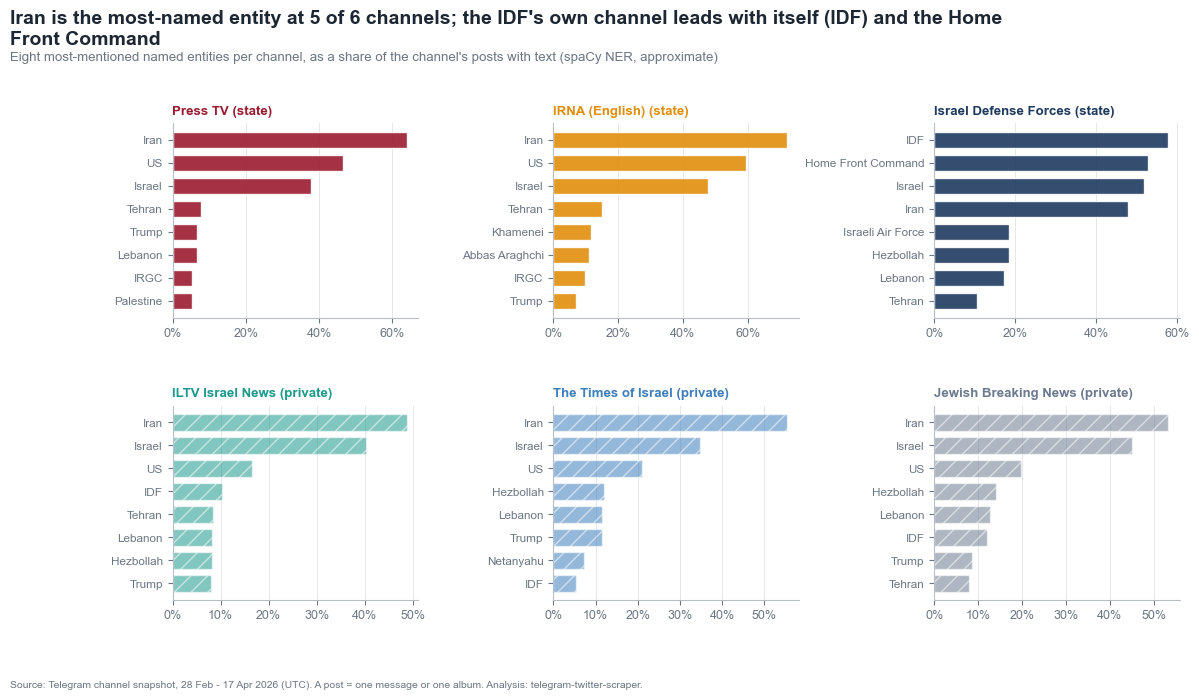

In [3]:
top = (ents.groupby(["channel_slug", "entity"]).size().rename("posts").reset_index())
top["share_of_posts"] = top["posts"] / top["channel_slug"].map(n_text)
top_n = top.sort_values(["channel_slug", "posts"], ascending=[True, False]).groupby("channel_slug").head(8)
board = top_n.assign(rank=top_n.groupby("channel_slug").cumcount() + 1).pivot(index="rank", columns="channel_slug", values="entity")[CHANNEL_ORDER]
board.columns = [SHORT_NAMES[c] for c in board.columns]
display(board)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
for ax, slug in zip(axes.ravel(), CHANNEL_ORDER):
    sub = top_n[top_n["channel_slug"] == slug].sort_values("share_of_posts")
    ax.barh(sub["entity"], sub["share_of_posts"], color=viz.CHANNEL_COLORS[slug], alpha=0.9 if CHANNELS[slug]["ownership"] == "state" else 0.55, hatch=None if CHANNELS[slug]["ownership"] == "state" else "//", edgecolor="white", height=0.7)
    ax.set_title(f"{CHANNELS[slug]['name']} ({CHANNELS[slug]['ownership']})", fontsize=9.5, color=viz.CHANNEL_COLORS[slug])
    ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
fig.subplots_adjust(hspace=0.45, wspace=0.55)
first = {s: top_n[top_n["channel_slug"] == s].sort_values("posts", ascending=False).iloc[0] for s in CHANNEL_ORDER}
n_iran_top = sum(first[s]["entity"] == "Iran" for s in CHANNEL_ORDER)
viz.headline(fig, f"Iran is the most-named entity at {n_iran_top} of 6 channels; the IDF's own channel leads with itself ({first['idfofficial']['entity']}) and the Home Front Command",
             "Eight most-mentioned named entities per channel, as a share of the channel's posts with text (spaCy NER, approximate)", y=1.0, wrap=110)
viz.done(fig, "04_top_entities", top_n)

**Reading the figure.** Iran is the top entity at Press TV, IRNA, ILTV, ToI and JBN, followed by the US and Israel at the two Iranian channels and by Israel and the US at the three private Israeli ones (the same three names in a different order). The IDF's own channel puts itself and the Home Front Command first, because most of its posts are alert templates. Below the top three the lists diverge as the topic model predicted: IRNA names Khamenei, Araghchi and the IRGC, Press TV Tehran, Trump, Lebanon, the IRGC and Palestine; ToI and JBN name Hezbollah and Lebanon, and ToI also Netanyahu. NER is approximate (for example "Tehran" is counted separately from "Iran"), so use these as a rough ranking and the regex-based shares below for any number quoted.

## 2. Actor emphasis: who gets named?

Named-entity recognition is noisy for a few names the article cares about, so the key actors are matched with explicit regular expressions instead (case-insensitive, word-bounded). Each cell is the share of a channel's posts naming the actor, with a Wilson 95% interval in the exported data. The IDF's own channel naming "IDF" is trivially high and is shown but greyed in the reading.

channel_slug,Press TV,IRNA,IDF,ILTV,ToI,JBN
actor,,,,,,
Trump,7.8,8.6,0.0,9.2,19.1,11.6
Netanyahu,1.3,2.2,0.0,5.7,7.4,2.9
Khamenei / Mojtaba,4.9,20.2,0.6,6.8,3.7,3.5
Araghchi,2.6,12.5,0.0,0.2,0.2,0.4
Hezbollah,3.6,1.8,19.5,8.3,12.4,14.9
IRGC,7.4,10.8,4.9,2.8,1.8,6.1
IDF,1.6,4.9,64.6,15.5,12.4,18.1
Hormuz,4.7,8.6,0.1,1.1,4.3,4.4


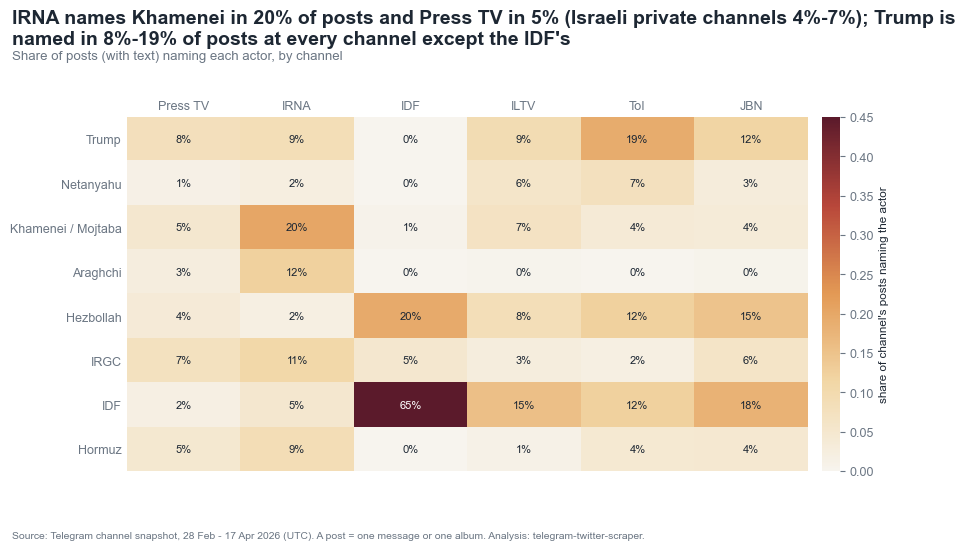

In [4]:
ACTORS = {
    "Trump": r"\bTrump\b",
    "Netanyahu": r"\bNetanyahu\b",
    "Khamenei / Mojtaba": r"\bKhamenei\b|\bMojtaba\b",
    "Araghchi": r"\bAraghchi\b",
    "Hezbollah": r"\bHezbollah\b",
    "IRGC": r"\bIRGC\b|Revolutionary Guard",
    "IDF": r"\bIDF\b|Israel(?:i)? Defen[cs]e Forces|Israeli (?:army|military)",
    "Hormuz": r"\bHormuz\b",
}
tx = posts[posts["has_clean_text"]]
parts = []
for name, pattern in ACTORS.items():
    t = stats.keyword_share(tx, pattern, "channel_slug", text_col="clean_text").assign(actor=name)
    parts.append(t)
actors = pd.concat(parts, ignore_index=True)
share_w = actors.pivot(index="actor", columns="channel_slug", values="share").reindex(list(ACTORS))[CHANNEL_ORDER]
display((share_w.rename(columns=SHORT_NAMES) * 100).round(1))

fig, ax = plt.subplots(figsize=(9.2, 4.6))
viz.annotated_heatmap(ax, share_w.rename(columns=SHORT_NAMES), fmt="{:.0%}", vmax=0.45, cbar_label="share of channel's posts naming the actor")
viz.color_channel_ticklabels(ax, axis="x")
ax.xaxis.tick_top()
mj = share_w.loc["Khamenei / Mojtaba"]; tr = share_w.loc["Trump"]
mj = share_w.loc["Khamenei / Mojtaba"]; tr = share_w.loc["Trump"]
isr = ["iltvnews", "thetimesofisrael2022", "jewishbreakingnewstelegram"]
viz.headline(fig, f"IRNA names Khamenei in {mj['irna-en']:.0%} of posts and Press TV in {mj['presstv']:.0%} (Israeli private channels {mj[isr].min():.0%}-{mj[isr].max():.0%}); Trump is named in {tr.drop('idfofficial').min():.0%}-{tr.drop('idfofficial').max():.0%} of posts at every channel except the IDF's",
             "Share of posts (with text) naming each actor, by channel", y=1.03, wrap=100)
viz.done(fig, "04_actor_emphasis", actors)

**Reading the figure.** IRNA names Khamenei or Mojtaba in 20% of its posts and Press TV in 5%; the Israeli private channels in 4-7% and the IDF in 0.6%. Araghchi is an IRNA actor (12.5% against 0.2-2.6% elsewhere). Trump is named in 8-19% of posts at every channel except the IDF (0%), most at ToI (19%) and least at Press TV (8%); Netanyahu is named 1-2% at the Iranian channels and 3-7% at the private Israeli ones. Hezbollah is an Israeli-side topic (IDF 20%, JBN 15%, ToI 12%, ILTV 8% against 2-4% on the Iranian channels), and the IRGC an Iranian-side one (IRNA 11%, Press TV 7%, ILTV and ToI 2-3%). The IDF's own acronym is in 65% of the IDF's posts (self-reference) and 12-18% of the private Israeli channels'.

## 3. The Iran-Israel-US triangle

How often does a post name all three corners? Each post is tagged for whether it mentions Iran (Iran/Iranian/Tehran), Israel (Israel/Israeli/IDF/Jerusalem/Tel Aviv/Zionist) and the US (US/American/United States/Washington/Trump/Pentagon). The networks show, per channel, how many posts name each corner (node size) and each pair together (edge width).

measure,Iran,Israel,US,pair_Iran_Israel,pair_Iran_US,pair_Israel_US,triangle
channel_slug,,,,,,,
Press TV,68.6,45.3,51.7,31.8,40.3,28.6,24.2
IRNA,79.9,56.9,63.9,50.1,56.3,48.7,45.4
IDF,51.8,76.6,1.3,51.2,1.0,1.3,1.0
ILTV,53.7,53.7,22.0,29.7,15.9,9.8,7.2
ToI,56.6,48.6,34.6,25.2,26.8,13.5,9.5
JBN,57.1,57.4,31.1,32.4,20.8,10.2,7.7


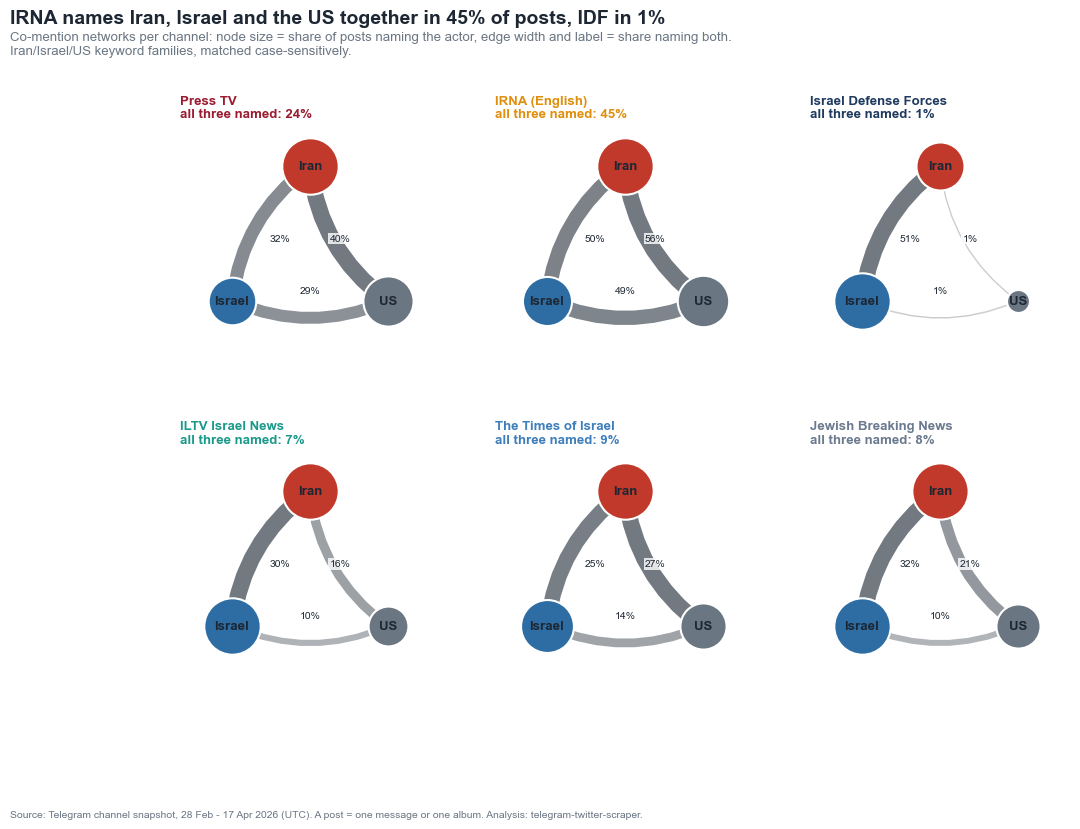

In [5]:
CORNERS = {
    "Iran": r"\bIran(?:ian|ians)?\b|\bTehran\b",
    "Israel": r"\bIsrael(?:i|is)?\b|\bIDF\b|\bJerusalem\b|\bTel Aviv\b|\bZionist",
    "US": r"\bUS\b|\bU\.S\.|\bAmerican?s?\b|\bUnited States\b|\bWashington\b|\bTrump\b|\bPentagon\b",
}
flags = pd.DataFrame({k: tx["clean_text"].str.contains(p, regex=True) for k, p in CORNERS.items()})
flags["channel_slug"] = tx["channel_slug"].to_numpy()
flags["pair_Iran_Israel"] = flags["Iran"] & flags["Israel"]; flags["pair_Iran_US"] = flags["Iran"] & flags["US"]; flags["pair_Israel_US"] = flags["Israel"] & flags["US"]
flags["triangle"] = flags["Iran"] & flags["Israel"] & flags["US"]
tri_rows = []
for col in ["Iran", "Israel", "US", "pair_Iran_Israel", "pair_Iran_US", "pair_Israel_US", "triangle"]:
    tri_rows.append(stats.share_table(flags, "channel_slug", col).assign(measure=col))
tri = pd.concat(tri_rows, ignore_index=True)
tri_w = tri.pivot(index="channel_slug", columns="measure", values="share").reindex(CHANNEL_ORDER)
display((tri_w * 100).round(1).rename(index=SHORT_NAMES))

fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
for ax, slug in zip(axes.ravel(), CHANNEL_ORDER):
    r = tri_w.loc[slug]
    viz.circular_network(ax, ["Iran", "Israel", "US"], {("Iran", "Israel"): r["pair_Iran_Israel"], ("Iran", "US"): r["pair_Iran_US"], ("Israel", "US"): r["pair_Israel_US"]},
                         node_size={"Iran": r["Iran"], "Israel": r["Israel"], "US": r["US"]}, node_color={"Iran": "#C0392B", "Israel": "#2E6DA4", "US": "#6B7683"}, edge_label_min=0.0, label_fmt="{:.0%}")
    ax.set_title(f"{CHANNELS[slug]['name']}\nall three named: {r['triangle']:.0%}", fontsize=9.5, color=viz.CHANNEL_COLORS[slug])
fig.subplots_adjust(hspace=0.25, wspace=0.05)
hi, lo = tri_w["triangle"].idxmax(), tri_w["triangle"].idxmin()
viz.headline(fig, f"{SHORT_NAMES[hi]} names Iran, Israel and the US together in {tri_w.loc[hi, 'triangle']:.0%} of posts, {SHORT_NAMES[lo]} in {tri_w.loc[lo, 'triangle']:.0%}",
             "Co-mention networks per channel: node size = share of posts naming the actor, edge width and label = share naming both. Iran/Israel/US keyword families, matched case-sensitively.", y=1.01, wrap=100)
viz.done(fig, "04_triangle_network", tri)

**Reading the figure.** Iran appears in 52-80% of posts everywhere and Israel in 45-77%, so those two corners are not discriminating. What differs is the US: it appears in 64% of IRNA's posts, 52% of Press TV's, 35% of ToI's, 31% of JBN's and 22% of ILTV's, and in 1.3% of the IDF's. As a result the full triangle (all three named) is 45% of IRNA's posts and 24% of Press TV's, against 9.5% of ToI's, 7.7% of JBN's and 7.2% of ILTV's. The Iranian state outlets frame the war as a three-party relationship (Iran-US 40-56%, Iran-Israel 32-50%, Israel-US 29-49%), the private Israeli outlets as Iran-Israel (25-32%) with the US as a minor third party (Israel-US 10-14%). The IDF is a two-party channel (Iran-Israel 51%).

In [6]:
_ = study.record_findings("04_actors", {
    "ner_model": f"spaCy {spacy.__version__} {nlp.meta['name']} {nlp.meta['version']}",
    "top_entities": top_n[["channel_slug", "entity", "posts", "share_of_posts"]],
    "actor_shares": actors,
    "triangle_shares": tri,
})

## What this means for the article

- **"The same Iran-Israel-US triangle" is only half true.** Every channel is about Iran and Israel; the *US* is the dividing line (US named in 52-64% of Iranian state posts and 22-35% of the private Israeli posts, 1% of the IDF's).
- **Actor emphasis is asymmetric in a quotable way**: Iranian state outlets name their own diplomats and the IRGC (Araghchi 12.5% at IRNA); Israeli private channels name Hezbollah, Trump and Netanyahu.
- **Caveat the regexes**: US is matched case-sensitively and includes Trump/Washington/Pentagon; Israel includes IDF, Jerusalem and Tel Aviv; the IDF channel names itself by construction.